# 8 · Neural network

```{math}
a = \sigma(Wx + b)
```

**Family:** neural networks · **Task:** classification

The video's last frame is a fully connected network. Each layer applies the same
linear-then-squash step as logistic regression, $a^{(\ell)} = \sigma(W^{(\ell)}a^{(\ell-1)} + b^{(\ell)})$,
and stacking layers lets the boundary bend. Here: 2 inputs → 8 → 8 hidden units with
$\tanh$ activation → 1 sigmoid output, trained by backpropagation with Adam.

## Imports

`ml8` is the book's own package; [The sample data](00_sample_data.ipynb) explains how it is
imported. This chapter uses:

| File | What this chapter uses |
|---|---|
| `ml8/data.py` | `data.moons_arrays`: two-moons train and test arrays (`X_train, y_train, X_test, y_test`) |
| `ml8/scratch.py` | `scratch.sigmoid`: the function $\sigma(z)$ |
| `ml8/models.py` | `models.train_mlp`: trains a scikit-learn `MLPClassifier` one epoch at a time<br>`models.NN_EPOCHS`: the training epochs to compare |
| `ml8/plotting.py` | `P.plot_surface`: draws a decision surface and the points<br>the palette (`P.BG`, `P.BLUE`, `P.FG`, `P.RED`, `P.YELLOW`) |

In [1]:
# ml8 sits one folder above notebooks/, so put that folder on Python's search path
import sys
sys.path.insert(0, "..")

# Installed packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The book's own modules
from ml8 import data              # ml8/data.py: the seeded sample datasets
from ml8 import models            # ml8/models.py: shared model settings
from ml8 import plotting as P     # ml8/plotting.py: colours and plot helpers
from ml8 import scratch           # ml8/scratch.py: the from-scratch formulas

P.use_style()  # the dark style used by every figure
pd.set_option("display.precision", 4)

In [2]:
Xtr, ytr, Xte, yte = data.moons_arrays()
mlp, hist, surfaces = models.train_mlp(Xtr, ytr, X_test=Xte, y_test=yte)
hist = pd.DataFrame(hist).set_index("epoch")
hist.loc[models.NN_EPOCHS]

,loss,train_acc,test_acc
epoch,,,
1,0.5580,0.8286,0.8250
10,0.3091,0.8714,0.8417
25,0.1950,0.9179,0.9167
50,0.1797,0.9179,0.9250
100,0.1743,0.9143,0.9167
200,0.1524,0.9500,0.9250
400,0.1249,0.9571,0.9333


## The formula, by hand

A forward pass is just the formula applied layer by layer. Using the trained weights,
it reproduces scikit-learn's `predict_proba` exactly.

In [3]:
def forward(X, coefs, intercepts):
    a = X
    for W, b in zip(coefs[:-1], intercepts[:-1]):
        a = np.tanh(a @ W + b)                    # hidden layers: σ = tanh
    return scratch.sigmoid(a @ coefs[-1] + intercepts[-1]).ravel()   # output: logistic

mine = forward(Xte, mlp.coefs_, mlp.intercepts_)
print("matches predict_proba:", np.allclose(mine, mlp.predict_proba(Xte)[:, 1]))
print("weight shapes:", [W.shape for W in mlp.coefs_], "· parameters:", sum(W.size + b.size for W, b in zip(mlp.coefs_, mlp.intercepts_)))

matches predict_proba: True
weight shapes: [(2, 8), (8, 8), (8, 1)] · parameters: 105


## Learning the boundary

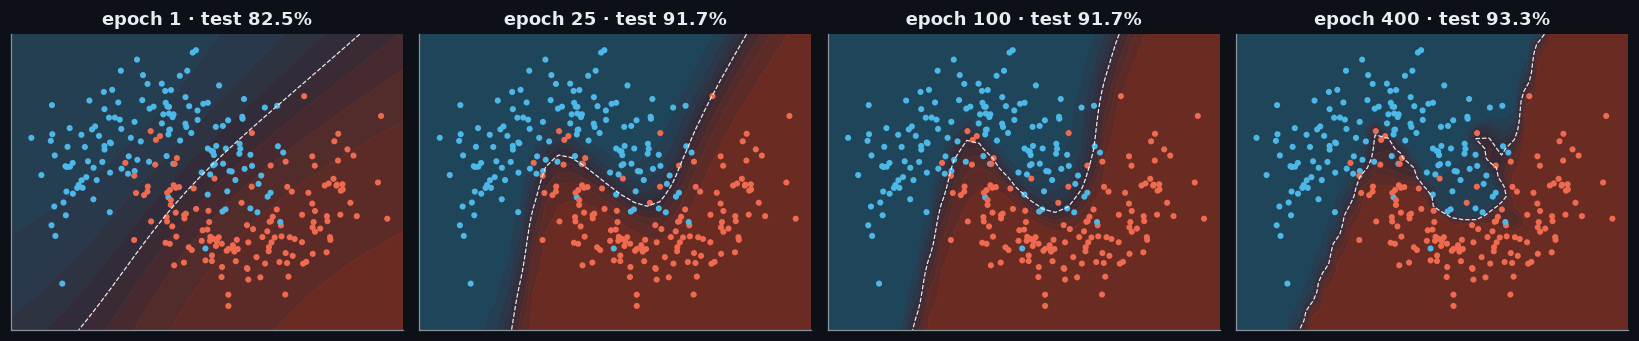

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, ep in zip(axes, [1, 25, 100, 400]):
    P.plot_surface(ax, surfaces[ep], Xtr, ytr, title=f"epoch {ep} · test {hist.loc[ep, 'test_acc']:.1%}")
plt.tight_layout()

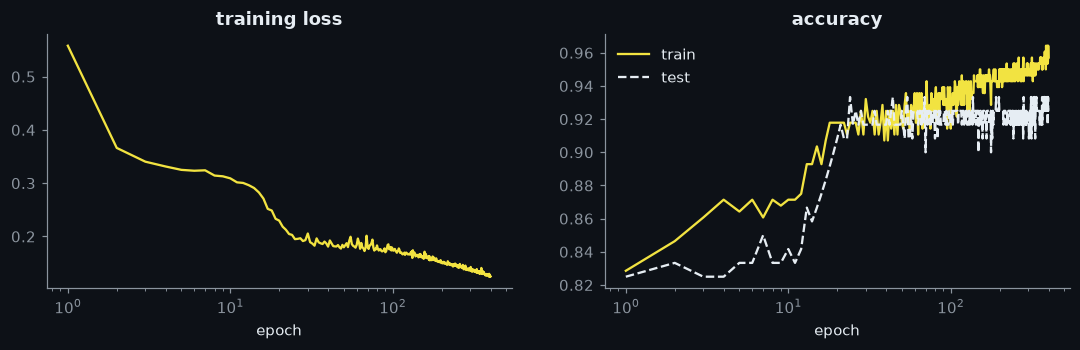

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(hist.index, hist.loss, c=P.YELLOW); ax[0].set_xscale("log"); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist.index, hist.train_acc, c=P.YELLOW, label="train")
ax[1].plot(hist.index, hist.test_acc, c=P.FG, ls="--", label="test")
ax[1].set_xscale("log"); ax[1].legend(frameon=False); ax[1].set_title("accuracy"); ax[1].set_xlabel("epoch");

## The trained network

Line width is the weight's magnitude; red is positive, blue negative.

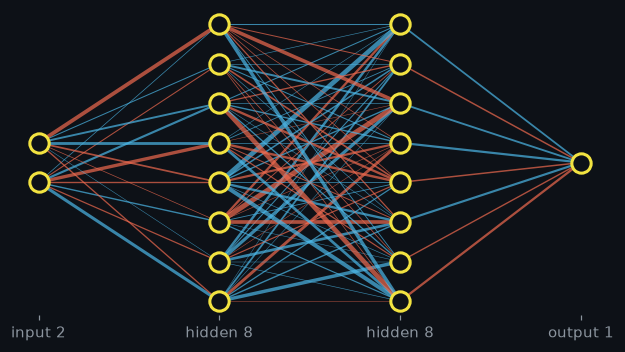

In [6]:
sizes = [mlp.coefs_[0].shape[0]] + [W.shape[1] for W in mlp.coefs_]
pos = {(l, i): (l, i - (n - 1) / 2) for l, n in enumerate(sizes) for i in range(n)}
wmax = max(np.abs(W).max() for W in mlp.coefs_)
fig, ax = plt.subplots(figsize=(7, 3.6))
for l, W in enumerate(mlp.coefs_):
    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            (x0, y0), (x1, y1) = pos[(l, i)], pos[(l + 1, j)]
            ax.plot([x0, x1], [y0, y1], c=P.RED if W[i, j] > 0 else P.BLUE, lw=0.3 + 3 * abs(W[i, j]) / wmax, alpha=0.7)
for (l, i), (x0, y0) in pos.items():
    ax.scatter(x0, y0, s=160, facecolors=P.BG, edgecolors=P.YELLOW, linewidths=2, zorder=3)
names = ["input"] + ["hidden"] * (len(sizes) - 2) + ["output"]
ax.set_xticks(range(len(sizes)), [f"{n} {s}" for n, s in zip(names, sizes)])
ax.set_yticks([]); ax.spines[:].set_visible(False);

**Try it:** set `NN_HIDDEN = (2,)` in `ml8/models.py`. With two hidden units the
network can only draw a gently bent line; add units and the boundary can follow the
moons.